# Лабораторная работа 3: Кластеризация

---

## Цель работы
Изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.


## Постановка задачи
1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5. Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.


## Описание датасета
Iris dataset - Классификации цветков ириса (https://www.kaggle.com/datasets/himanshunakrani/iris-dataset)

Датасет включает 4 факторов и 1 целевую переменную.

Свойства:
1. Длина чашелистика (Sepal_Length) — длина чашелистика в сантиметрах.
2. Ширина чашелистика (Sepal_Width) — ширина чашелистика в сантиметрах.
3. Длина лепестка (Petal_Length) — длина лепестка в сантиметрах.
4. Ширина лепестка (Petal_Width) — ширина лепестка в сантиметрах.

Целевая переменная:

5. Вид ириса (Species) — категориальная переменная, определяющая вид цветка.

В датасете представлены три класса ирисов:
- Iris setosa;

- Iris versicolor;

- Iris virginica.

Стандартный набор данных содержит 150 наблюдений, по 50 объектов каждого класса.



In [8]:
import os
import glob
import warnings

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
from scipy.optimize import linear_sum_assignment

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif, mutual_info_classif

from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
    rand_score,
    adjusted_mutual_info_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    jaccard_score,
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 10

RANDOM_STATE = 42
K_RANGE = list(range(2, 11))

path = kagglehub.dataset_download("himanshunakrani/iris-dataset")

csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True,
)

if not csv_files:
    raise FileNotFoundError("CSV-файл не найден!")

df = pd.read_csv(csv_files[0])

print("Первая строка датасета:")
print(df.head(1).to_string())

print("\nРазмерность датасета:", df.shape)

print("\nИнформация о датасете:")
df.info()

print("\nОбщее количество пропусков:", int(df.isnull().sum().sum()))
print("Количество дубликатов:", int(df.duplicated().sum()))

Первая строка датасета:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa

Размерность датасета: (150, 5)

Информация о датасете:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

Общее количество пропусков: 0
Количество дубликатов: 3


В результате первичного анализа датасета Iris установлено, что он содержит 150 наблюдений и 5 столбцов, включающих 4 числовых признака и 1 категориальный признак, обозначающий вид цветка. Все данные имеют корректные типы, пропущенные значения отсутствуют. При проверке выявлено 3 дублирующихся наблюдения, которые не будут удалены, поскольку совпадение измерений не свидетельствует об ошибке и является естественным для исследуемых объектов. 


Используемые числовые признаки:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Количество объектов: 150
Количество признаков: 4

Найдена целевая переменная 'species':
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


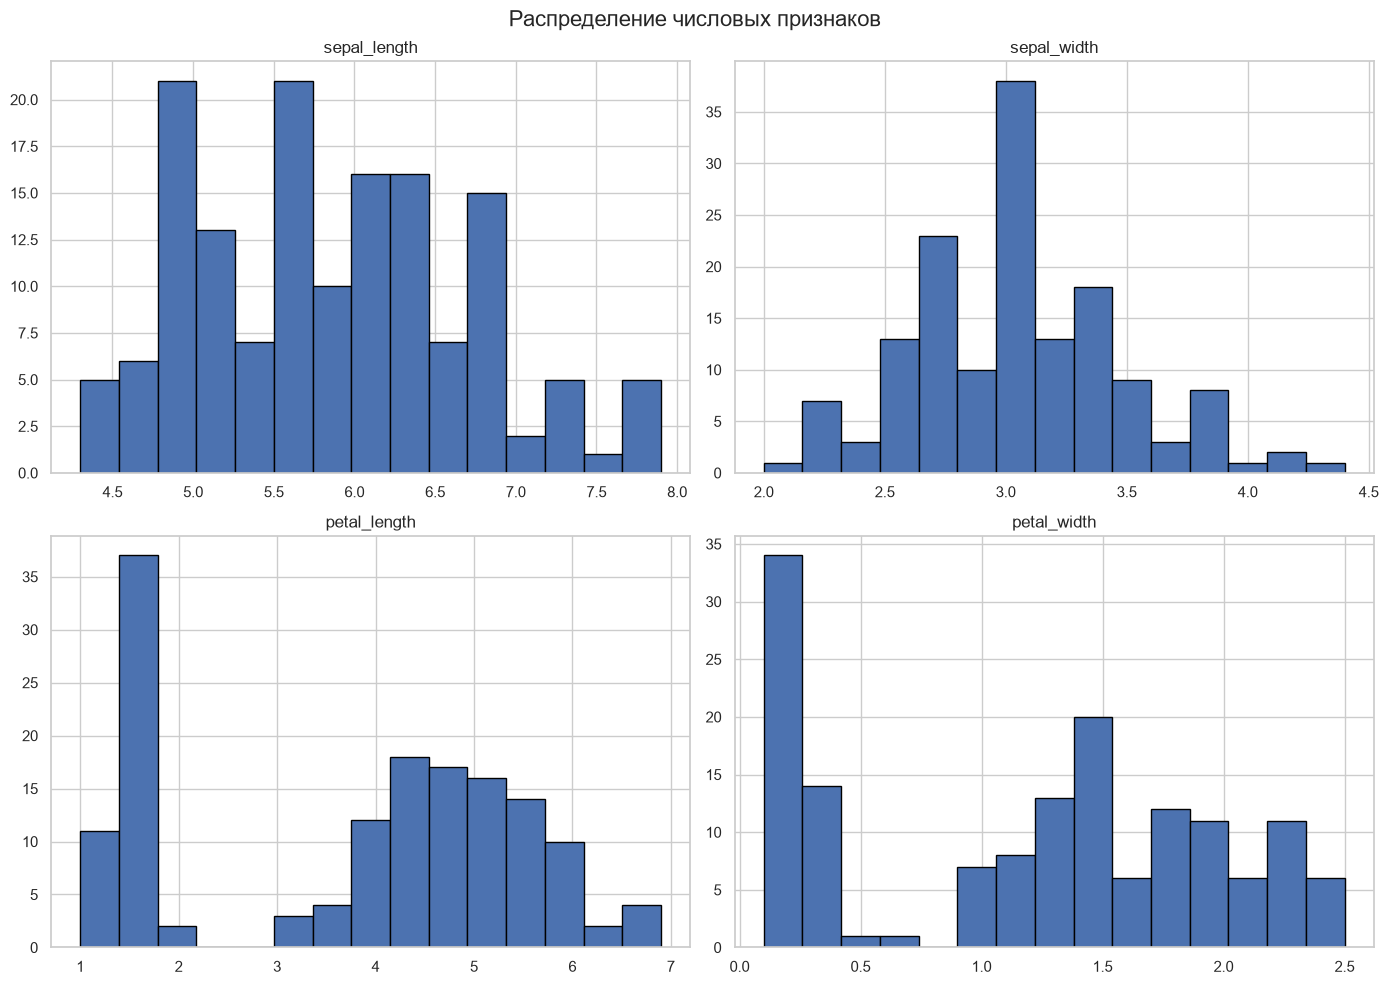


Характеристики распределения признаков:
              Среднее  Стд. откл.  Асимметрия (Skew)  Эксцесс (Kurtosis)
sepal_length   5.8433      0.8281             0.3149             -0.5521
sepal_width    3.0540      0.4336             0.3341              0.2908
petal_length   3.7587      1.7644            -0.2745             -1.4019
petal_width    1.1987      0.7632            -0.1050             -1.3398


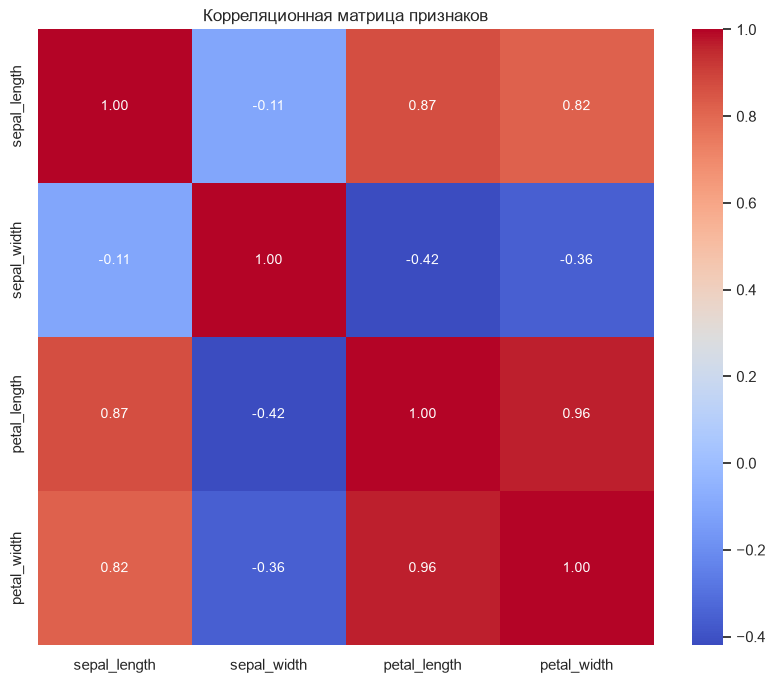

In [10]:
target_candidates = ["species", "class", "variety", "target", "type"]
target_col = next(
    (col for col in df.columns if col.strip().lower() in target_candidates),
    None,
)

y = df[target_col].copy() if target_col is not None else None

technical_cols = [
    col for col in df.columns if col.strip().lower() in ["id", "unnamed: 0"]
]

X = df.select_dtypes(include=np.number).copy()
X.drop(columns=technical_cols, inplace=True, errors="ignore")
X = X.dropna(axis=1, how="all")
X = X.fillna(X.median())

print("\nИспользуемые числовые признаки:")
print(X.columns.tolist())
print("Количество объектов:", X.shape[0])
print("Количество признаков:", X.shape[1])

if y is not None:
    print(f"\nНайдена целевая переменная '{target_col}':")
    print(y.value_counts())
else:
    print("\nЦелевая переменная не найдена")

X.hist(bins=15, figsize=(14, 10), edgecolor="black")
plt.suptitle("Распределение числовых признаков", fontsize=16)
plt.tight_layout()
plt.show()

dist_stats = pd.DataFrame({
    "Среднее": X.mean(),
    "Стд. откл.": X.std(),
    "Асимметрия (Skew)": X.skew(),
    "Эксцесс (Kurtosis)": X.kurtosis(),
})
print("\nХарактеристики распределения признаков:")
print(dist_stats.round(4))

corr_matrix = X.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
)
plt.title("Корреляционная матрица признаков")
plt.show()

В исходной таблице присутствует категориальный целевой признак species, включающий 3 сбалансированных класса (setosa, versicolor, virginica — по 50 объектов в каждом). Для соблюдения условий обучения без учителя данный столбец исключён из матрицы признаков $X$ и сохранён исключительно для последующей внешней оценки качества кластеризации. 

Разные диапазоны значений и стандартные отклонения признаков (например, petal_length имеет среднее $3.7587$ и $\sigma = 1.7644$, тогда как petal_width — среднее $1.1987$ и $\sigma = 0.7632$) подтверждают необходимость обязательной стандартизации перед применением метрических алгоритмов.  

Анализ распределений признаков (близость к нормальному):

Оценка формы распределений проводилась визуально по гистограммам. Формальные статистические тесты нормальности, такие как Критерий Шапиро — Уилка, не применялись, поэтому выводы о распределениях носят описательный характер.

Признаки чашелистика (sepal_length, sepal_width): имеют умеренную правостороннюю асимметрию ($\text{Skew} = 0.3149$ и $0.3341$). Наиболее близким к унимодальному нормальному распределению является sepal_width ($\text{Kurtosis} = 0.2908$), с выраженным пиком в районе $3.0$. У sepal_length распределение более пологое ($\text{Kurtosis} = -0.5521$).   

Признаки лепестка (petal_length, petal_width): демонстрируют ярко выраженную бимодальность (наличие двух изолированных пиков на гистограммах) и значительный отрицательный эксцесс ($\text{Kurtosis} = -1.4019$ и $-1.3398$), при этом коэффициенты асимметрии невелики ($-0.2745$ и $-0.1050$). Бимодальность указывает на наличие в выборке как минимум одной чётко обособленной группы объектов (малые значения лепестка в интервале $1.0\text{–}2.0$ для petal_length и $0.1\text{–}0.6$ для petal_width), что подтверждает осмысленность применения кластерного анализа.

Корреляционный анализ и информационная значимость признаков:

Наблюдается сильная положительная линейная связь между параметрами лепестка: коэффициент корреляции между petal_length и petal_width достигает $r = 0.96$.

Также выявлена высокая положительная корреляция длины чашелистика (sepal_length) с длиной ($r = 0.87$) и шириной ($r = 0.82$) лепестка.

Признак sepal_width слабо или умеренно отрицательно коррелирует с остальными переменными ($r$ от $-0.11$ до $-0.42$), неся независимую информацию о форме цветка. Высокая согласованность признаков petal_length, petal_width и sepal_length свидетельствует об их высокой разделительной способности при формировании кластеров.

In [19]:
f_vals, p_vals = f_classif(X_scaled, kmeans_labels)
importance_data = {
    "Признак": X.columns,
    "Стд. откл. (исх.)": X.std().values,
    "ANOVA F (по кластерам K-means)": f_vals,
    "p-value (ANOVA)": p_vals,
}

if y is not None:
    y_encoded_for_mi = pd.factorize(y)[0]
    mi_vals = mutual_info_classif(
        X_scaled,
        y_encoded_for_mi,
        random_state=RANDOM_STATE,
    )
    importance_data["Mutual Info (с классами y)"] = mi_vals

feature_importance_df = pd.DataFrame(importance_data).sort_values(
    "ANOVA F (по кластерам K-means)",
    ascending=False,
)

print("\nИнформационная значимость признаков:")
print(feature_importance_df.round(4).to_string(index=False))


Информационная значимость признаков:
     Признак  Стд. откл. (исх.)  ANOVA F (по кластерам K-means)  p-value (ANOVA)  Mutual Info (с классами y)
petal_length             1.7644                        847.6525              0.0                      0.9926
 petal_width             0.7632                        549.0411              0.0                      0.9856
sepal_length             0.8281                        156.9567              0.0                      0.5114
 sepal_width             0.4336                         81.3650              0.0                      0.2898


Для оценки вклада признаков в формирование кластерной структуры были рассчитаны F-статистики ANOVA на основе меток кластеров, полученных алгоритмом K-means. Однако такой подход имеет ограничение: поскольку кластеры сформированы непосредственно на основе рассматриваемых признаков, последующая проверка различий между ними по ANOVA является зависимой от исходной процедуры кластеризации (circular reasoning). Поэтому данный анализ носит описательный характер и не может рассматриваться как независимое статистическое подтверждение значимости признаков.

Ранжирование признаков по вкладу в кластеризацию (ANOVA F-test):

Все четыре признака статистически значимо различаются между кластерами K-means ($p\text{-value} = 0.0$ после округления), однако их разделительная способность распределена крайне неравномерно:

petal_length — безусловный лидер по значимости ($F = 847.6525$, наибольший разброс до масштабирования $\sigma = 1.7644$);

petal_width — второй по значимости признак ($F = 549.0411$, $\sigma = 0.7632$);

sepal_length — умеренно высокий вклад в разделение групп ($F = 156.9567$, $\sigma = 0.8281$);

sepal_width — наименьшая $F$-статистика ($F = 81.3650$, наименьший разброс $\sigma = 0.4336$), что указывает на более слабую самостоятельную разделимость по этому признаку. 

Согласованность с целевой переменной y (Mutual Info):
Для независимой оценки информативности признаков относительно истинной целевой переменной species была использована взаимная информация (Mutual Information, MI). В отличие от ANOVA по меткам K-means, этот показатель оценивает связь между признаками и реальными классами объектов.

Оценки взаимной информации с классами species подтверждают ту же иерархию: наибольший объём информации о принадлежности к виду несут petal_length ($\text{MI} = 0.9926$) и petal_width ($\text{MI} = 0.9856$), далее следуют sepal_length ($\text{MI} = 0.5114$) и sepal_width ($\text{MI} = 0.2898$).

Параметры лепестка (petal_length и petal_width) играют ключевую роль в формировании кластерной структуры и разграничении групп, тогда как sepal_width носит вспомогательный характер и при этом особенно нуждается в стандартизации из-за меньшего исходного разброса.

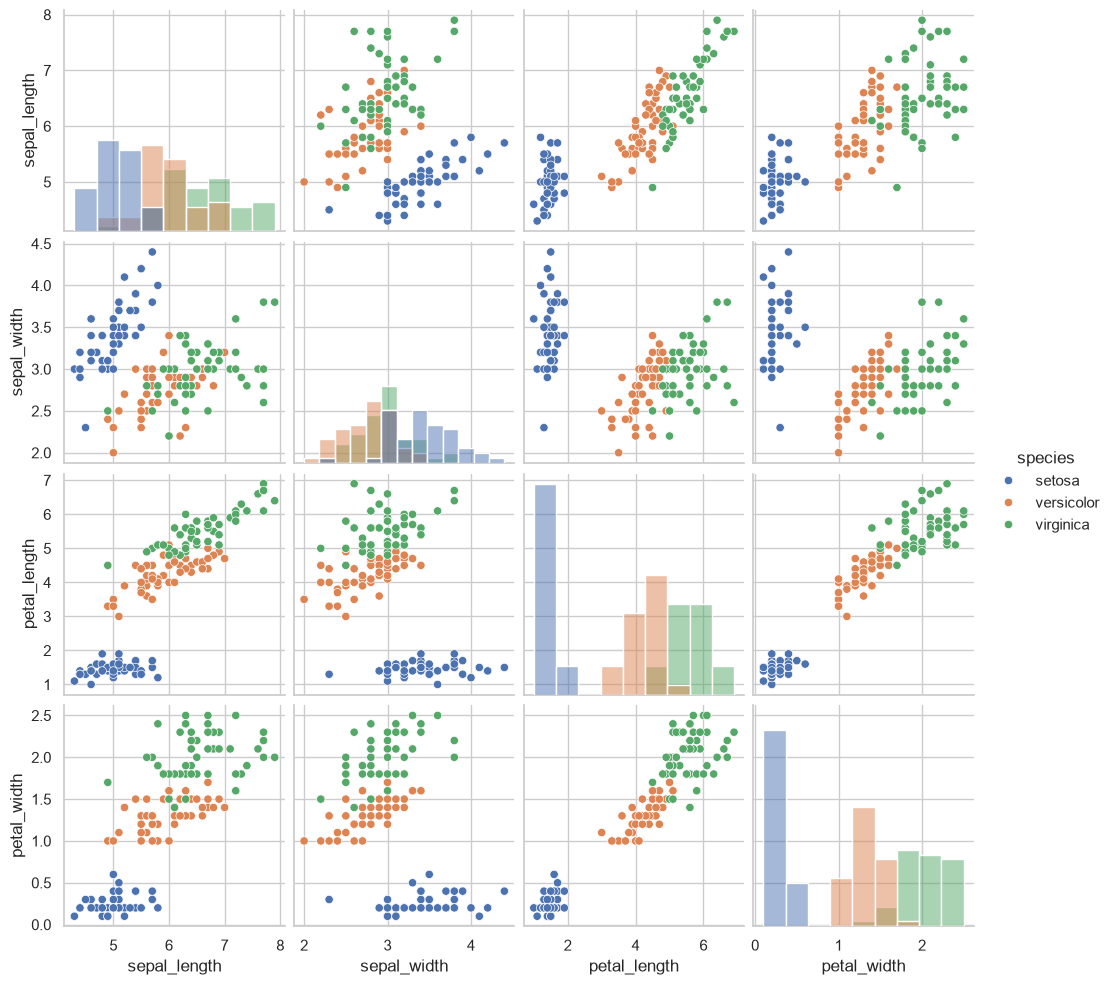

In [15]:
if y is not None:
    pairplot_data = X.copy()
    pairplot_data[target_col] = y.astype(str).values
    sns.pairplot(pairplot_data, hue=target_col, diag_kind="hist")
else:
    sns.pairplot(X, diag_kind="hist")

plt.show()

В пространстве признаков чётко выделяется один полностью изолированный, компактный кластер (соответствующий классу setosa), который отделён от остальных объектов широким зазором практически на всех проекциях, особенно с участием petal_length и petal_width (значения petal_length в пределах $1.0\text{–}1.9$, petal_width — $0.1\text{–}0.6$). Остальные наблюдения образуют второе крупное вытянутое облако, внутри которого прослеживаются две смежные подгруппы (versicolor со средними значениями лепестка $3.0\text{–}5.1$ по длине и $1.0\text{–}1.8$ по ширине и virginica с более крупными значениями $4.5\text{–}6.9$ и $1.4\text{–}2.5$ соответственно), имеющие небольшую зону перекрытия на границе. Таким образом, визуально структура данных допускает двухкластерное разбиение (чёткое отделение одной компактной группы от остальной массы) и трёхкластерное разбиение (детализация второго облака на две близкие по плотности подгруппы).

Форма и плотность: выделяемые группы имеют выпуклую (эллипсоидальную / близкую к сферической) форму без сложных нелинейных изгибов, колец или вложенных структур; плотность распределения точек внутри групп сопоставима, без разреженных «хвостов» шума.

Наиболее информативные пары признаков: лучшее визуальное разделение всех трёх групп наблюдается в координатах petal_length — petal_width и sepal_length — petal_length, где точки выстраиваются вдоль выраженной линейной зависимости. Напротив, в проекции sepal_length — sepal_width группы versicolor и virginica существенно накладываются друг на друга.

Итого

K-means (метод k-средних) оптимально подходит для данных с компактными, выпуклыми кластерами сопоставимого размера и плотности в евклидовом пространстве (после стандартизации StandardScaler), где каждую группу можно корректно описать её центроидом.

Иерархическая кластеризация (метод Уорда, linkage="ward") также минимизирует внутрикластерную дисперсию, не требует случайной инициализации центров и позволяет с помощью дендрограммы наглядно проследить иерархию разбиения — сначала отделение изолированного кластера (k = 2), а затем разделение более крупного скопления на две подгруппы (k = 3).


Анализ выбросов по правилу 1.5 * IQR:
     Признак  Нижняя граница  Верхняя граница  Выбросов  Доля, %
sepal_length            3.15             8.35         0     0.00
 sepal_width            2.05             4.05         4     2.67
petal_length           -3.65            10.35         0     0.00
 petal_width           -1.95             4.05         0     0.00


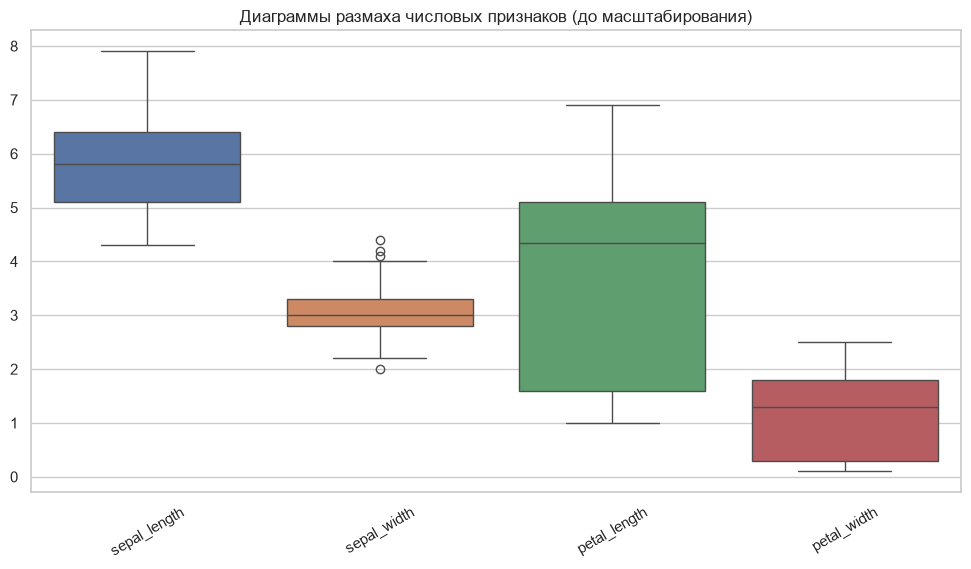

In [12]:
outliers_rows = []
for col in X.columns:
    q1 = X[col].quantile(0.25)
    q3 = X[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    mask = (X[col] < lower) | (X[col] > upper)
    outliers_rows.append({
        "Признак": col,
        "Нижняя граница": lower,
        "Верхняя граница": upper,
        "Выбросов": int(mask.sum()),
        "Доля, %": round(mask.mean() * 100, 2),
    })

outliers_df = pd.DataFrame(outliers_rows)
print("\nАнализ выбросов по правилу 1.5 * IQR:")
print(outliers_df.round(4).to_string(index=False))

plt.figure(figsize=(12, 6))
sns.boxplot(data=X)
plt.title("Диаграммы размаха числовых признаков (до масштабирования)")
plt.xticks(rotation=30)
plt.show()

Количественная оценка выбросов:

По признакам sepal_length (границы $[3.15;\; 8.35]$), petal_length ($[-3.65;\; 10.35]$) и petal_width ($[-1.95;\; 4.05]$) выбросов не выявлено ($0$ объектов, $0.00\%$).

Единичные выбросы обнаружены только по признаку sepal_width (границы $[2.05;\; 4.05]$): за пределы усов выходят 4 наблюдения, что составляет $2.67\%$ от общего объёма выборки (три значения выше верхней границы в диапазоне $4.1\text{–}4.4$ и одно значение ниже нижней границы на уровне $2.0$).  

Обнаруженные 4 выброса — 3 наблюдения вида setosa и 1 наблюдение вида versicolor, немногочисленны (\(2.67\%\) выборки), не являются экстремальными ошибками измерения и отражают естественную биологическую вариативность ирисов. При небольшом объёме данных (150 объектов) их удаление нецелесообразно, поскольку это может привести к потере информативных наблюдений и искусственному упрощению структуры данных. Поэтому выбросы сохранены для дальнейшего анализа.

Кроме того, в наборе данных присутствуют 3 дублирующихся наблюдения, которые также были сохранены. Их удаление не проводилось, чтобы не изменять исходный состав выборки и сохранить все наблюдения при последующем анализе кластеризации.

Сравнение масштабов и разброса признаков по диаграммам размаха (boxplot):

На графике наглядно видно различие в масштабах и разбросе переменных: наибольший межквартильный размах (высота «ящика») имеет признак petal_length (медиана около $4.35$, основная масса значений сосредоточена примерно от $1.6$ до $5.1$), тогда как sepal_width отличается самым узким межквартильным диапазоном (медиана $3.0$, ящик от $2.8$ до $3.3$).

Значительная разница в диапазонах и дисперсиях признаков дополнительно подтверждает необходимость стандартизации (StandardScaler) перед расчётом евклидовых расстояний.   


Первые 5 строк стандартизированных данных:
   sepal_length  sepal_width  petal_length  petal_width
0        -0.901        1.032        -1.341       -1.313
1        -1.143       -0.125        -1.341       -1.313
2        -1.385        0.338        -1.398       -1.313
3        -1.507        0.106        -1.284       -1.313
4        -1.022        1.263        -1.341       -1.313

Средние значения после StandardScaler:
sepal_length   -0.0
sepal_width    -0.0
petal_length    0.0
petal_width    -0.0
dtype: float64

Стандартные отклонения после StandardScaler:
sepal_length    1.0034
sepal_width     1.0034
petal_length    1.0034
petal_width     1.0034
dtype: float64


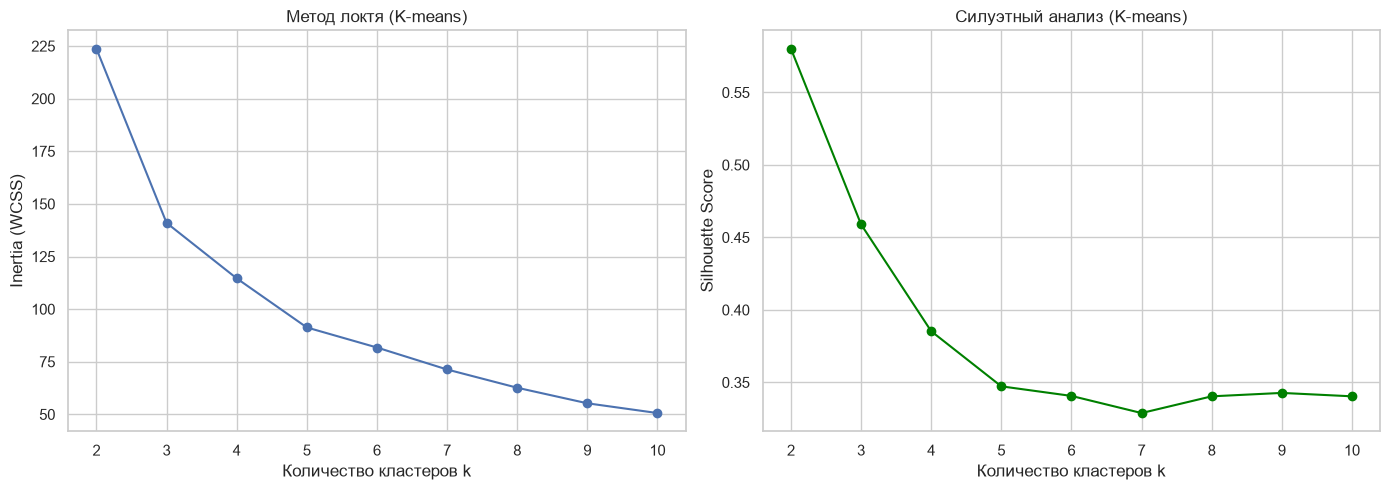


Оптимальное k для K-means по методу локтя: 5
Оптимальное k для K-means по силуэтному анализу: 2
Выбранное количество кластеров для K-means: 2


In [ ]:
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled_array, columns=X.columns, index=X.index)

print("\nПервые 5 строк стандартизированных данных:")
print(X_scaled.head().round(3))

print("\nСредние значения после StandardScaler:")
print(X_scaled.mean().round(4))

print("\nСтандартные отклонения после StandardScaler:")
print(X_scaled.std().round(4))

inertias = []
kmeans_silhouettes = []

for k in K_RANGE:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    kmeans_silhouettes.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(K_RANGE, inertias, marker="o")
axes[0].set_title("Метод локтя (K-means)")
axes[0].set_xlabel("Количество кластеров k")
axes[0].set_ylabel("Inertia (WCSS)")

axes[1].plot(K_RANGE, kmeans_silhouettes, marker="o", color="green")
axes[1].set_title("Силуэтный анализ (K-means)")
axes[1].set_xlabel("Количество кластеров k")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

best_k_silhouette = K_RANGE[int(np.argmax(kmeans_silhouettes))]

x_values = np.array(K_RANGE, dtype=float)
y_values = np.array(inertias, dtype=float)

x_norm = (x_values - x_values.min()) / (x_values.max() - x_values.min())
y_norm = (y_values - y_values.min()) / (y_values.max() - y_values.min())

line_y = y_norm[0] + (y_norm[-1] - y_norm[0]) * x_norm
distances_to_chord = np.abs(y_norm - line_y)
best_k_elbow = K_RANGE[int(np.argmax(distances_to_chord))]

print("\nОптимальное k для K-means по методу локтя:", best_k_elbow)
print("Оптимальное k для K-means по силуэтному анализу:", best_k_silhouette)

optimal_k = best_k_silhouette
print("Выбранное количество кластеров для K-means:", optimal_k)

Была проведена стандартизация так, как она устраняет доминирование признаков с большим исходным разбросом (petal_length) и обеспечивает корректный расчёт евклидовых расстояний.

Силуэтный анализ: максимальное значение Silhouette Score (около $0.58$) достигается при $k = 2$, после чего при увеличении $k$ метрика монотонно падает (примерно до $0.46$ при $k=3$, $0.385$ при $k=4$ и около $0.33\text{–}0.35$ при $k \ge 5$). Это отражает наиболее чёткое отделение одной изолированной группы от остального массива данных.

Метод локтя: на графике Inertia (WCSS) наблюдается резкое падение от $k=2$ (около $224$) к $k=3$ (около $140$), после чего уменьшение инерции становится более плавным. Автоматическая эвристика определения точки локтя, основанная на максимальном расстоянии от прямой хорды, определяет \(k=5\) (Inertia около \(91\)). Однако на фоне плавного изменения кривой эта точка может быть обусловлена особенностями эвристического алгоритма и не обязательно соответствует выраженному структурному перелому, поэтому \(k=5\) не рассматривается как однозначно оптимальное решение.

Выбор параметра: для дальнейшего обучения K-means выбрано значение \(k=2\), исходя из максимума Silhouette Score. Такое разбиение обеспечивает наиболее качественную структуру кластеров согласно внутренней метрике силуэта. (при этом значение $k=3$ также остаётся содержательно интересным для сопоставления с тремя видами ирисов при последующем анализе).

## Кластериазция методом K-means (K-средних)

In [16]:
kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

df_results = df.copy()
df_results["KMeans_Cluster"] = kmeans_labels

print("\nРазмеры кластеров K-means:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers_original, columns=X.columns)
centers_df.index.name = "Cluster"

print("\nЦентры кластеров K-means (в исходных единицах измерения):")
print(centers_df.round(3))


Размеры кластеров K-means:
0    100
1     50
Name: count, dtype: int64

Центры кластеров K-means (в исходных единицах измерения):
         sepal_length  sepal_width  petal_length  petal_width
Cluster                                                      
0               6.262        2.872         4.906        1.676
1               5.006        3.418         1.464        0.244


Выборку из 150 объектов алгоритм разделил на два кластера размером 100 объектов (кластер 0) и 50 объектов (кластер 1). Соотношение объёмов ($2:1$) точно соответствует структуре датасета Iris, где один обособленный вид насчитывает 50 экземпляров, а два других сходных вида в сумме составляют 100 экземпляров.

Кластер 1 (50 объектов — группа с мелкими лепестками): характеризуется компактным цветком с малыми длиной и шириной лепестка (petal_length = $1.464$, petal_width = $0.244$), меньшей длиной чашелистика (sepal_length = $5.006$), но более широким чашелистиком (sepal_width = $3.418$). По морфологическим характеристикам эта группа полностью соответствует виду Iris setosa.

Кластер 0 (100 объектов — группа с крупными лепестками): отличается значительно более крупными параметрами лепестка (petal_length = $4.906$, petal_width = $1.676$ — более чем в 3 и 6 раз выше, чем у кластера 1), большей длиной чашелистика (sepal_length = $6.262$) и более узким чашелистиком (sepal_width = $2.872$). Данный кластер объединяет экземпляры видов Iris versicolor и Iris virginica.

Наибольший вклад в разграничение двух кластеров вносят признаки лепестка (petal_length и petal_width), центры которых максимально удалены друг от друга, тогда как различия по ширине чашелистика (sepal_width) выражены слабее.

## Иерархическая кластеризация

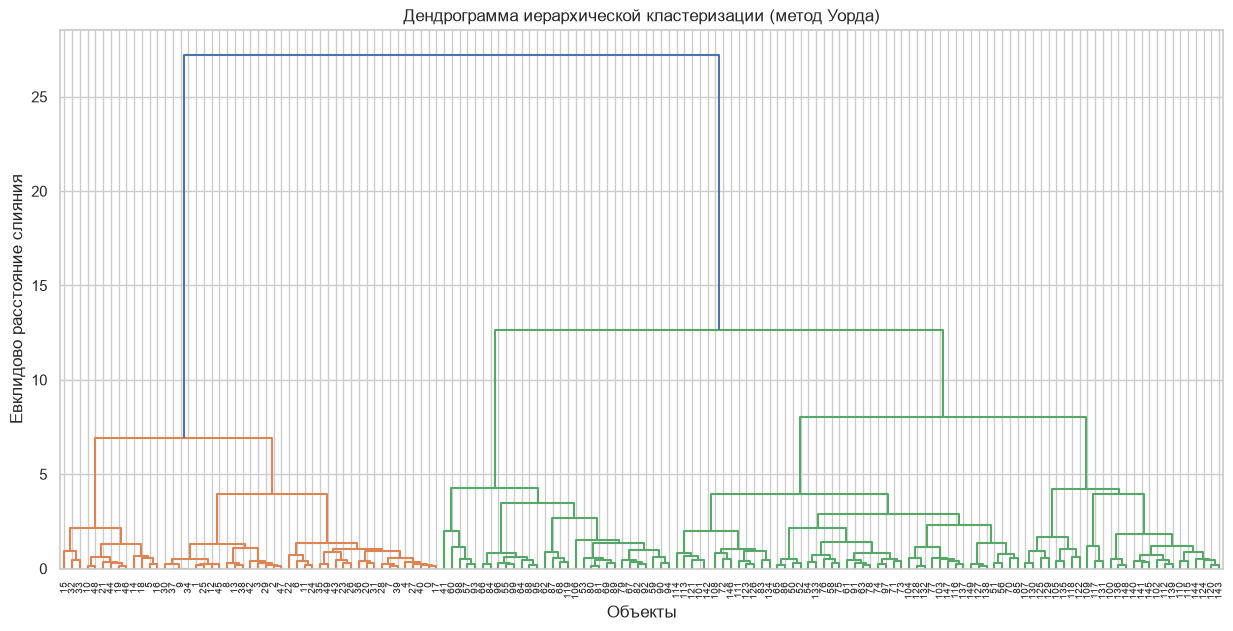

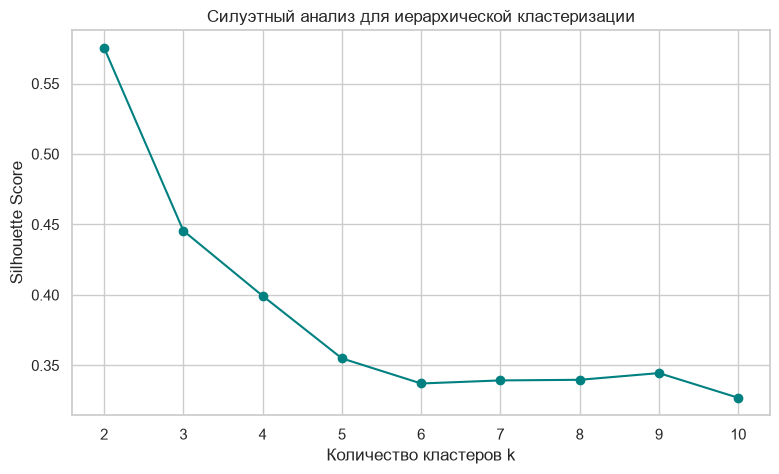


Оптимальное k для иерархической кластеризации по силуэту: 2

Размеры кластеров иерархической кластеризации:
0    101
1     49
Name: count, dtype: int64


In [17]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(15, 7))
dendrogram(Z, leaf_rotation=90, leaf_font_size=7)
plt.title("Дендрограмма иерархической кластеризации (метод Уорда)")
plt.xlabel("Объекты")
plt.ylabel("Евклидово расстояние слияния")
plt.show()

hierarchical_scores = []
for k in K_RANGE:
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_scaled)
    hierarchical_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(9, 5))
plt.plot(K_RANGE, hierarchical_scores, marker="o", color="teal")
plt.title("Силуэтный анализ для иерархической кластеризации")
plt.xlabel("Количество кластеров k")
plt.ylabel("Silhouette Score")
plt.show()

best_k_hierarchical = K_RANGE[int(np.argmax(hierarchical_scores))]
print("\nОптимальное k для иерархической кластеризации по силуэту:", best_k_hierarchical)

hierarchical = AgglomerativeClustering(n_clusters=best_k_hierarchical, linkage="ward")
hierarchical_labels = hierarchical.fit_predict(X_scaled)

df_results["Hierarchical_Cluster"] = hierarchical_labels

print("\nРазмеры кластеров иерархической кластеризации:")
print(pd.Series(hierarchical_labels).value_counts().sort_index())

Анализ дендрограммы:

На дендрограмме наблюдается наиболее выраженный скачок евклидова расстояния слияния при объединении двух последних крупных ветвей (высота слияния около $27.3$, тогда как предыдущее объединение происходит на уровне около $12.8$). Сечение дерева на высоте $15\text{–}25$ выделяет 2 крупных кластера (левую оранжевую ветвь и правую зелёную ветвь), а сечение на уровне $9\text{–}12$ делит правую ветвь ещё на две подгруппы, формируя 3 кластера с расстоянием последующих слияний около $7\text{–}8$.

Выбор оптимального количества кластеров по силуэтному анализу:

График зависимости Silhouette Score от числа кластеров $k$ для иерархического алгоритма повторяет динамику K-means: максимальное значение метрики (около $0.577$) достигается при $k = 2$, далее при $k = 3$ показатель снижается примерно до $0.445$, а при $k \ge 5$ стабилизируется в диапазоне $0.33\text{–}0.35$. Согласованность максимума силуэта и наибольшего разрыва по высоте на дендрограмме подтверждает выбор $k = 2$ в качестве оптимального числа кластеров.   

Наполняемость кластеров и сравнение с K-means:

При $k = 2$ иерархический алгоритм сформировал группы размером 101 объект (кластер 0) и 49 объектов (кластер 1).Полученное разбиение практически идентично результату K-means ($100$ и $50$ объектов) — расхождение составляет всего 1 пограничный объект, который в иерархической модели был отнесён к более крупному кластеру. Это свидетельствует о высокой устойчивости выделяемой структуры данных.

In [18]:
def calculate_internal_metrics(X_data, labels, method_name):
    return {
        "Метод": method_name,
        "Число кластеров": len(np.unique(labels)),
        "Silhouette Score": silhouette_score(X_data, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_data, labels),
        "Davies-Bouldin": davies_bouldin_score(X_data, labels),
    }


metrics_kmeans = calculate_internal_metrics(X_scaled, kmeans_labels, "K-means")
metrics_hierarchical = calculate_internal_metrics(
    X_scaled,
    hierarchical_labels,
    "Hierarchical",
)

metrics_df = pd.DataFrame([metrics_kmeans, metrics_hierarchical])
print("\nСравнение внутренних метрик качества:")
print(metrics_df.round(4).to_string(index=False))


def calculate_external_metrics(y_true, labels, method_name):
    y_encoded = pd.factorize(y_true)[0]

    contingency = pd.crosstab(
        pd.Series(y_encoded, name="True"),
        pd.Series(labels, name="Cluster"),
    )
    row_ind, col_ind = linear_sum_assignment(-contingency.values)
    mapping = {
        contingency.columns[c]: contingency.index[r]
        for r, c in zip(row_ind, col_ind)
    }
    mapped_labels = np.array([mapping.get(label, -1) for label in labels])

    return {
        "Метод": method_name,
        "ARI": adjusted_rand_score(y_encoded, labels),
        "Rand Index": rand_score(y_encoded, labels),
        "AMI": adjusted_mutual_info_score(y_encoded, labels),
        "NMI": normalized_mutual_info_score(y_encoded, labels),
        "Homogeneity": homogeneity_score(y_encoded, labels),
        "Completeness": completeness_score(y_encoded, labels),
        "V-measure": v_measure_score(y_encoded, labels),
        "Jaccard (macro)": jaccard_score(
            y_encoded,
            mapped_labels,
            average="macro",
            zero_division=0,
        ),
    }


if y is not None:
    external_kmeans = calculate_external_metrics(y, kmeans_labels, "K-means")
    external_hierarchical = calculate_external_metrics(
        y,
        hierarchical_labels,
        "Hierarchical",
    )
    external_df = pd.DataFrame([external_kmeans, external_hierarchical])
    print("\nВнешние метрики качества:")
    print(external_df.round(4).to_string(index=False))
else:
    external_df = None
    print("\nВнешние метрики не вычислялись: метки классов отсутствуют.")


Сравнение внутренних метрик качества:
       Метод  Число кластеров  Silhouette Score  Calinski-Harabasz  Davies-Bouldin
     K-means                2            0.5802           248.9034          0.5976
Hierarchical                2            0.5754           237.8259          0.5963

Внешние метрики качества:
       Метод    ARI  Rand Index    AMI    NMI  Homogeneity  Completeness  V-measure  Jaccard (macro)
     K-means 0.5681      0.7763 0.7316 0.7337       0.5794        1.0000     0.7337           0.5000
Hierarchical 0.5438      0.7630 0.6900 0.6925       0.5453        0.9483     0.6925           0.4917


Сравнение внутренних метрик качества :

Silhouette Score: у метода K-means показатель составляет $0.5802$, а у иерархической кластеризации — $0.5754$. Значения выше $0.5$ свидетельствуют о чётко выраженной кластерной структуре, где объекты расположены существенно ближе к центрам своих кластеров, чем к соседним.

Calinski-Harabasz Index: для K-means равен $248.9034$, для Hierarchical — $237.8259$. Более высокое значение у K-means подтверждает лучшее отношение межкластерной дисперсии к внутрикластерной.

Davies–Bouldin Index (чем меньше, тем лучше): иерархическая кластеризация (Ward) показывает немного более низкое значение — \(0.5963\) против \(0.5976\) у K-means. Формально это указывает на незначительное преимущество Ward по данной метрике, однако разница составляет всего \(0.0013\), что настолько мало, что не позволяет считать её существенным преимуществом и может находиться в пределах вариативности оценки.

Таким образом, по Silhouette Score и Calinski–Harabasz преимущество принадлежит K-means, тогда как по Davies–Bouldin — Hierarchical (Ward), но разница между методами практически минимальна. 

Сравнение внешних метрик качества:

Completeness и Homogeneity: Для K-means полнота (Completeness) достигает \(1.0000\). Это означает, что каждый истинный вид ирисов целиком попал в один кластер, то есть объекты одного вида не распределились между разными кластерами. Однако это не означает, что каждому виду соответствует отдельный кластер. Однородность (Homogeneity) составляет \(0.5794\), что отражает смешение классов: виды versicolor и virginica объединены в один кластер, тогда как setosa выделяется отдельно. У иерархической кластеризации полнота немного ниже (\(0.9483\)), что связано с разделением одного истинного класса между кластерами из-за отнесения пограничного объекта к соседней группе.

ARI, NMI и V-measure: по всем интегральным метрикам согласованности с истинной разметкой K-means опережает иерархический метод: $\text{ARI} = 0.5681$ против $0.5438$, $\text{NMI} = 0.7337$ против $0.6925$, $\text{V-measure} = 0.7337$ против $0.6925$.

Rand Index и Jaccard (macro): K-means также показывает более высокие значения Rand Index (\(0.7763\) против \(0.7630\)) и Jaccard macro (\(0.5000\) против \(0.4917\)). При этом Jaccard (macro) в данном анализе представляет собой классификационную метрику Jaccard, рассчитанную после оптимального сопоставления кластеров с истинными классами с помощью алгоритма Венгера (Hungarian algorithm), а не парный Jaccard, оценивающий совпадение пар объектов. Значение Jaccard \(=0.5\) свидетельствует об умеренном совпадении кластеризации с истинной разметкой, а не о безошибочном выделении классов. Оно отражает частичное совпадение групп, при котором один вид выделяется достаточно хорошо, но два других остаются объединёнными в одном кластере.

Общее сравнение алгоритмов:

Оба метода формируют достаточно качественное разбиение при \(k=2\) и демонстрируют близкие значения внутренних метрик. K-means имеет небольшое преимущество по Silhouette Score и Calinski–Harabasz, а иерархическая кластеризация Ward — по Davies–Bouldin, однако разница по последней метрике крайне мала и практически несущественна.

По внешним метрикам K-means также показывает более высокую согласованность с истинной разметкой. При этом Completeness \(=1.0\) означает сохранение целостности каждого истинного вида внутри одного кластера, но не полное разделение видов, поскольку versicolor и virginica объединены. Значение Jaccard \(=0.5\) дополнительно подтверждает, что совпадение с истинной классификацией является умеренным, а не идеальным.

В целом, в рамках данного эксперимента K-means демонстрирует несколько более предпочтительные показатели качества кластеризации, но оба алгоритма при \(k=2\) преимущественно разделяют Iris на две группы, а не воспроизводят исходные три вида с полной точностью.

In [21]:
def analyze_distances(X_data, labels, method_name):
    X_array = np.asarray(X_data)
    unique_labels = np.unique(labels)

    centers = []
    intra_distances = []
    cluster_sizes = {}

    for cluster_id in unique_labels:
        cluster_data = X_array[labels == cluster_id]
        cluster_sizes[cluster_id] = len(cluster_data)
        centers.append(cluster_data.mean(axis=0))

        if len(cluster_data) > 1:
            dists = pdist(cluster_data, metric="euclidean")
            intra_distances.append(float(dists.mean()))
        else:
            intra_distances.append(0.0)

    centers = np.array(centers)
    inter_distances = squareform(pdist(centers, metric="euclidean"))

    print(f"Анализ расстояний: {method_name}")
    print("Размеры кластеров:", cluster_sizes)
    print("Средние внутрикластерные расстояния:")
    for cluster_id, distance in zip(unique_labels, intra_distances):
        print(f"  Кластер {cluster_id}: {distance:.4f}")

    print("\nМатрица евклидовых расстояний между центрами кластеров:")
    print(
        pd.DataFrame(
            inter_distances,
            index=unique_labels,
            columns=unique_labels,
        ).round(3)
    )

    print(
        "\nСреднее внутрикластерное расстояние:",
        round(float(np.mean(intra_distances)), 4),
    )

    if len(inter_distances) > 1:
        upper_vals = inter_distances[np.triu_indices(len(inter_distances), k=1)]
        print("Минимальное межкластерное расстояние:", round(float(upper_vals.min()), 4))
        print("Максимальное межкластерное расстояние:", round(float(upper_vals.max()), 4))

    return centers, intra_distances, inter_distances


centers_kmeans, intra_kmeans, inter_kmeans = analyze_distances(
    X_scaled,
    kmeans_labels,
    "K-means",
)

centers_hierarchical, intra_hierarchical, inter_hierarchical = analyze_distances(
    X_scaled,
    hierarchical_labels,
    "Иерархическая кластеризация",
)


Анализ расстояний: K-means
Размеры кластеров: {np.int32(0): 100, np.int32(1): 50}
Средние внутрикластерные расстояния:
  Кластер 0: 1.6801
  Кластер 1: 1.1874

Матрица евклидовых расстояний между центрами кластеров:
      0     1
0  0.00  3.36
1  3.36  0.00

Среднее внутрикластерное расстояние: 1.4337
Минимальное межкластерное расстояние: 3.3598
Максимальное межкластерное расстояние: 3.3598
Анализ расстояний: Иерархическая кластеризация
Размеры кластеров: {np.int64(0): 101, np.int64(1): 49}
Средние внутрикластерные расстояния:
  Кластер 0: 1.7219
  Кластер 1: 1.1227

Матрица евклидовых расстояний между центрами кластеров:
       0      1
0  0.000  3.348
1  3.348  0.000

Среднее внутрикластерное расстояние: 1.4223
Минимальное межкластерное расстояние: 3.3481
Максимальное межкластерное расстояние: 3.3481


Компактность кластеров (внутрикластерные расстояния):

В обоих алгоритмах кластер 1 (изолированная группа из 50 объектов в K-means и 49 объектов в иерархической кластеризации) обладает существенно более высокой компактностью: среднее попарное евклидово расстояние внутри него составляет $1.1874$ для K-means и $1.1227$ для иерархического метода. 

Кластер 0 (более крупная группа из 100 и 101 объекта соответственно) имеет больший разброс точек: среднее внутрикластерное расстояние равно $1.6801$ (K-means) и $1.7219$ (Hierarchical), что объясняется объединением в нём двух близких подгрупп (versicolor и virginica).

Среднее внутрикластерное расстояние по всем группам составляет $1.4337$ для K-means и $1.4223$ для иерархической кластеризации.  
 
 
Отделимость кластеров (межкластерные расстояния):

Евклидово расстояние между центрами кластеров 0 и 1 в стандартизированном пространстве признаков равно $3.3598$ для K-means и $3.3481$ для иерархической кластеризации (поскольку $k = 2$, минимальное и максимальное межкластерные расстояния совпадают).

Межкластерное расстояние примерно в 2.35 раза превышает среднее внутрикластерное расстояние ($3.3598$ против $1.4337$), что количественно подтверждает хорошую разделимость и устойчивость выделенных групп в пространстве признаков.   

Сравнение методов по геометрии разбиения:

Оба метода формируют практически одинаковую геометрическую структуру: различие в расстоянии между центрами составляет всего $0.0117$ ($3.3598$ против $3.3481$), при этом K-means обеспечивает чуть более компактный крупный кластер ($1.6801$ против $1.7219$) и немного большее удаление центров друг от друга.


Зависимость метрик K-means от параметра k:
 k  Inertia  Silhouette  Calinski-Harabasz  Davies-Bouldin
 2 223.7320      0.5802           248.9034          0.5976
 3 140.9658      0.4590           239.3418          0.8354
 4 114.6179      0.3853           206.0929          0.8727
 5  91.2954      0.3473           201.9875          0.9406
 6  81.7566      0.3407           182.5591          1.0077
 7  71.3198      0.3288           176.6719          0.9939
 8  62.6518      0.3404           173.9854          0.9124
 9  55.2618      0.3427           173.7367          0.9025
10  50.6232      0.3404           168.8133          0.8926


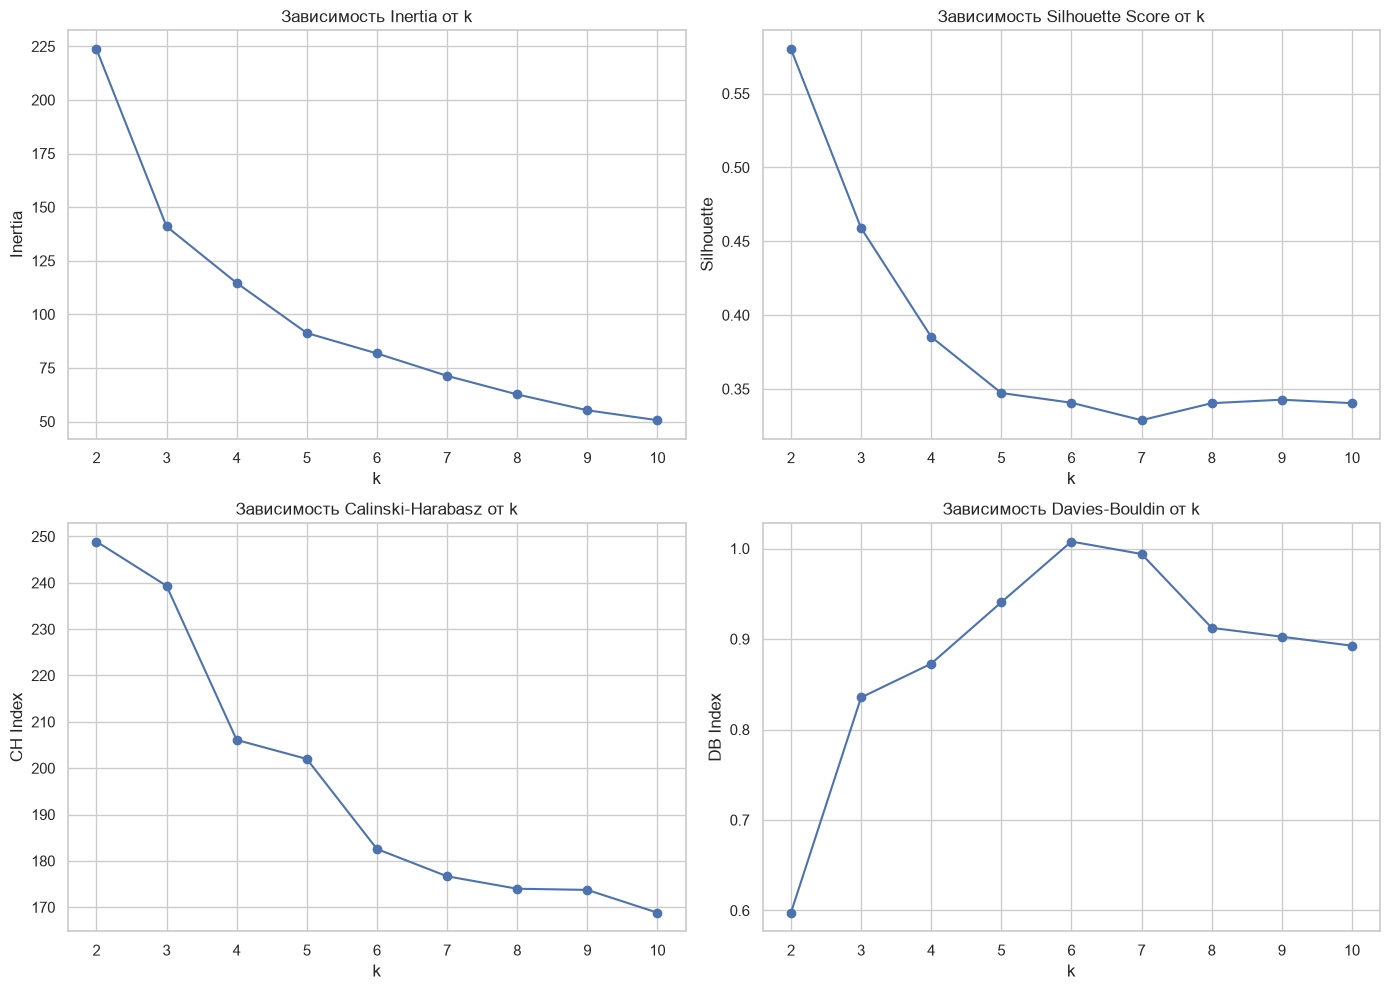


Устойчивость K-means (ARI по seeds [0, 1, 7, 21, 42, 99, 123]): среднее=1.0000, мин=1.0000, макс=1.0000


In [ ]:
results_k = []
for k in K_RANGE:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    results_k.append({
        "k": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_scaled, labels),
        "Davies-Bouldin": davies_bouldin_score(X_scaled, labels),
    })

parameter_df = pd.DataFrame(results_k)
print("\nЗависимость метрик K-means от параметра k:")
print(parameter_df.round(4).to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].plot(parameter_df["k"], parameter_df["Inertia"], marker="o")
axes[0, 0].set_title("Зависимость Inertia от k")
axes[0, 0].set_xlabel("k")
axes[0, 0].set_ylabel("Inertia")

axes[0, 1].plot(parameter_df["k"], parameter_df["Silhouette"], marker="o")
axes[0, 1].set_title("Зависимость Silhouette Score от k")
axes[0, 1].set_xlabel("k")
axes[0, 1].set_ylabel("Silhouette")

axes[1, 0].plot(parameter_df["k"], parameter_df["Calinski-Harabasz"], marker="o")
axes[1, 0].set_title("Зависимость Calinski-Harabasz от k")
axes[1, 0].set_xlabel("k")
axes[1, 0].set_ylabel("CH Index")

axes[1, 1].plot(parameter_df["k"], parameter_df["Davies-Bouldin"], marker="o")
axes[1, 1].set_title("Зависимость Davies-Bouldin от k")
axes[1, 1].set_xlabel("k")
axes[1, 1].set_ylabel("DB Index")

plt.tight_layout()
plt.show()

seeds = [0, 1, 7, 21, 42, 99, 123]
stability_scores = []
for seed in seeds:
    alt_model = KMeans(n_clusters=optimal_k, random_state=seed, n_init=10)
    alt_labels = alt_model.fit_predict(X_scaled)
    stability_scores.append(adjusted_rand_score(kmeans_labels, alt_labels))

print(
    f"\nУстойчивость K-means (ARI по seeds {seeds}): "
    f"среднее={np.mean(stability_scores):.4f}, "
    f"мин={np.min(stability_scores):.4f}, макс={np.max(stability_scores):.4f}"
)

Динамика метрик качества при изменении числа кластеров $k$ (от $2$ до $10$):

Inertia (WCSS). Inertia монотонно уменьшается с ростом числа кластеров: от \(223.7320\) при \(k=2\) до \(140.9658\) при \(k=3\), \(91.2954\) при \(k=5\) и \(50.6232\) при \(k=10\). Это закономерно, поскольку увеличение числа кластеров приводит к уменьшению внутрикластерной суммы квадратов расстояний до центроидов. Однако дальнейшее снижение Inertia сопровождается дроблением групп на более мелкие подмножества, что не обязательно улучшает содержательное качество кластеризации.

Silhouette Score. Максимальное значение достигается при \(k=2\) (\(0.5802\)). При \(k=3\) метрика снижается до \(0.4590\), а при \(k \geq 5\) держится в диапазоне \(0.3288\text{–}0.3473\). Это указывает на ухудшение компактности кластеров и их отделимости при увеличении числа групп по сравнению с разбиением на два кластера.

Calinski-Harabasz Index: наибольшее значение наблюдается при $k=2$ ($248.9034$), далее снижается к $k=3$ ($239.3418$), резко падает при $k=4$ ($206.0929$) и продолжает уменьшаться до $168.8133$ при $k=10$, подтверждая наилучшее соотношение межкластерной и внутрикластерной дисперсий при малом числе кластеров.

Davies-Bouldin Index (чем меньше, тем лучше): наилучший (наименьший) показатель зафиксирован при $k=2$ ($0.5976$); при $k=3$ он возрастает до $0.8354$, достигает пика (наихудшего значения) при $k=6$ ($1.0077$), а затем колеблется в пределах $0.8926\text{–}0.9939$.   

Выбор оптимального $k$:

Все три основные метрики качества (Silhouette Score, Calinski-Harabasz и Davies-Bouldin) согласованно указывают на $k = 2$ как на наиболее чёткое и компактное разбиение в стандартизированном пространстве признаков, тогда как значение $k = 3$ выступает как содержательная альтернатива при необходимости разделить более крупную группу на две близкие подгруппы.  

Устойчивость разбиения при смене инициализации (random_state):

Для оценки устойчивости K-means было выполнено повторное обучение на семи значениях random_state — [0, 1, 7, 21, 42, 99, 123] при n_init=10. Сравнение полученных разбиений с базовым с помощью Adjusted Rand Index (ARI) показало одинаковые результаты во всех запусках: среднее, минимум и максимум ARI составили \(1.0000\).

Таким образом, все семь запусков дали идентичное кластерное разбиение. Это свидетельствует о высокой устойчивости и воспроизводимости K-means при \(k=2\) на данном наборе данных: в рамках проверенных инициализаций результат не зависел от выбора начальных центроидов.


Объясненная дисперсия компонентами PCA: [0.7277 0.2303]
Суммарная объясненная дисперсия (2 компоненты): 0.958

Нагрузки признаков на главные компоненты:
                PC1    PC2
sepal_length  0.522  0.372
sepal_width  -0.263  0.926
petal_length  0.581  0.021
petal_width   0.566  0.065


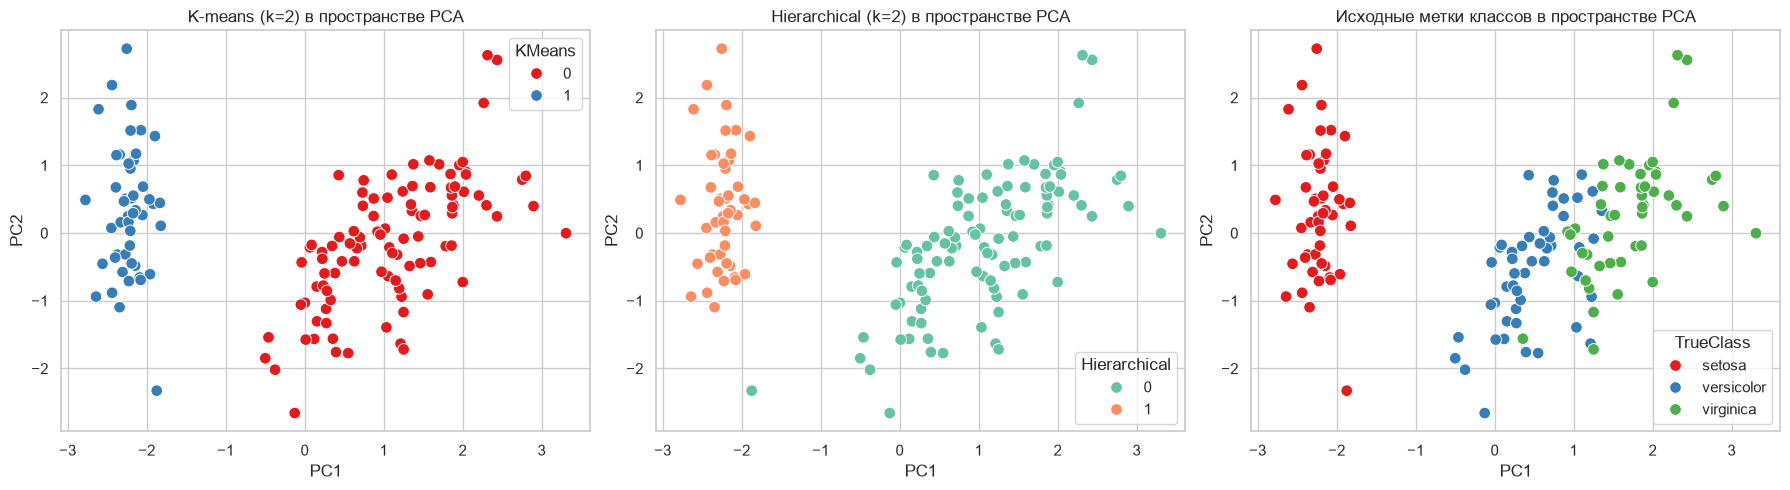

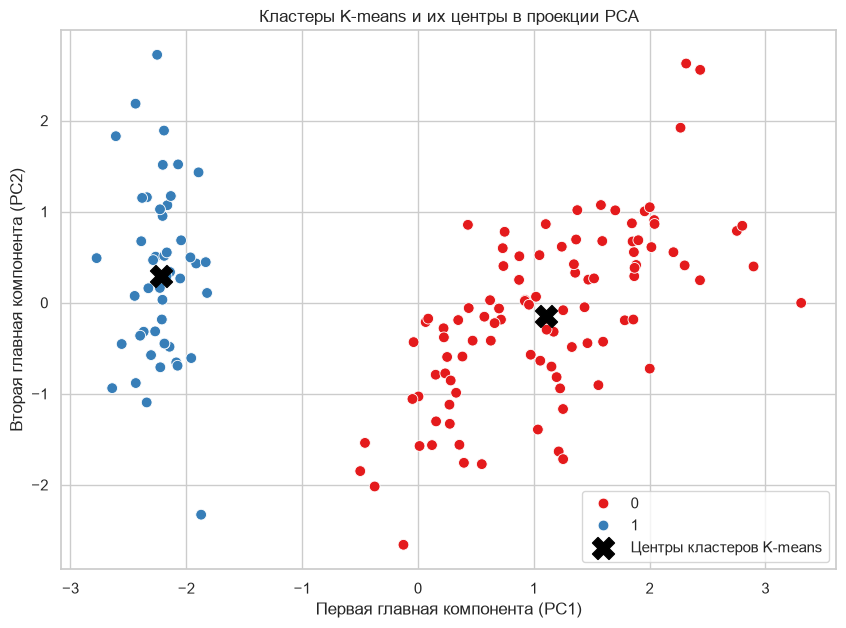


Средние значения признаков по кластерам K-means (исходный масштаб):
         sepal_length  sepal_width  petal_length  petal_width
Cluster                                                      
0               6.262        2.872         4.906        1.676
1               5.006        3.418         1.464        0.244


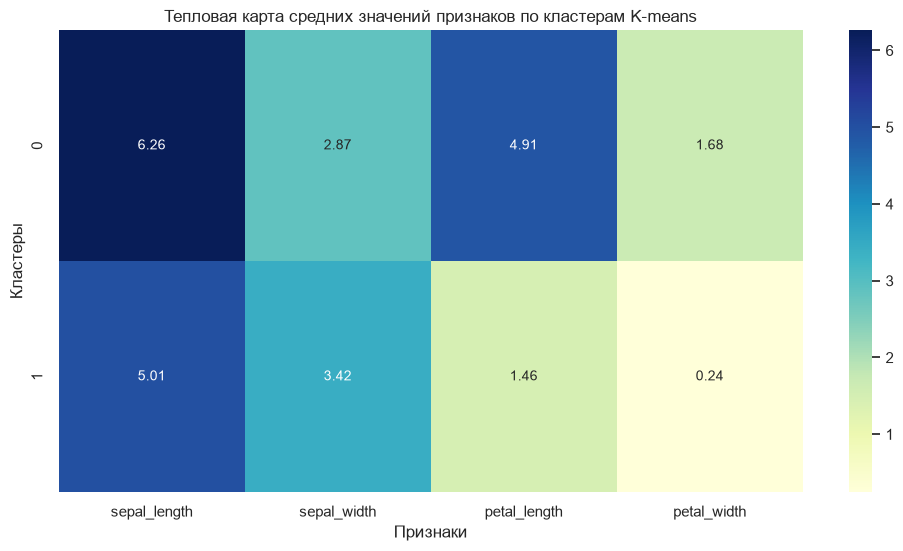


Таблица сопряженности (настоящие классы vs кластеры K-means):
Кластер K-means   0   1
Настоящий класс        
setosa            0  50
versicolor       50   0
virginica        50   0


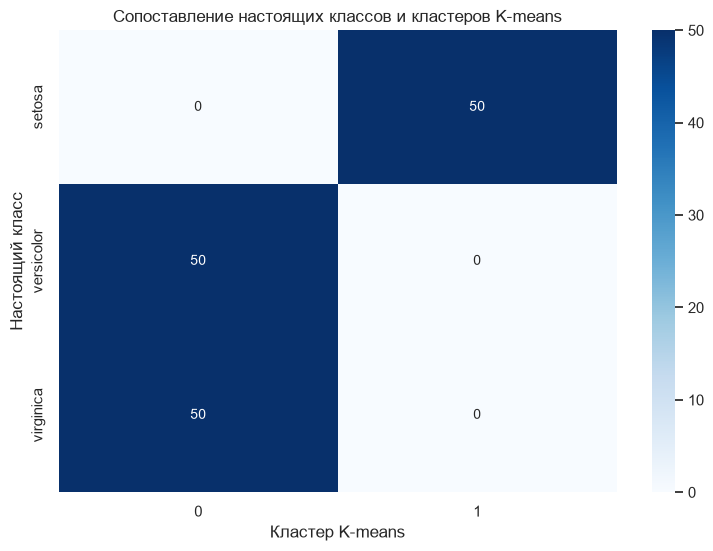

In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print("\nОбъясненная дисперсия компонентами PCA:", np.round(pca.explained_variance_ratio_, 4))
print("Суммарная объясненная дисперсия (2 компоненты):", round(float(pca.explained_variance_ratio_.sum()), 4))

loadings_df = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=["PC1", "PC2"],
)
print("\nНагрузки признаков на главные компоненты:")
print(loadings_df.round(3))

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans": kmeans_labels,
    "Hierarchical": hierarchical_labels,
})
if y is not None:
    pca_df["TrueClass"] = y.astype(str).values

n_plots = 3 if y is not None else 2
fig, axes = plt.subplots(1, n_plots, figsize=(6 * n_plots, 5))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="KMeans",
    palette="Set1",
    s=70,
    ax=axes[0],
)
axes[0].set_title(f"K-means (k={optimal_k}) в пространстве PCA")

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Hierarchical",
    palette="Set2",
    s=70,
    ax=axes[1],
)
axes[1].set_title(f"Hierarchical (k={best_k_hierarchical}) в пространстве PCA")

if y is not None:
    sns.scatterplot(
        data=pca_df,
        x="PC1",
        y="PC2",
        hue="TrueClass",
        palette="Set1",
        s=70,
        ax=axes[2],
    )
    axes[2].set_title("Исходные метки классов в пространстве PCA")

plt.tight_layout()
plt.show()

centers_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=kmeans_labels,
    palette="Set1",
    s=60,
)
plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    s=250,
    color="black",
    label="Центры кластеров K-means",
)
plt.title("Кластеры K-means и их центры в проекции PCA")
plt.xlabel("Первая главная компонента (PC1)")
plt.ylabel("Вторая главная компонента (PC2)")
plt.legend()
plt.show()

interpretation_df = X.copy()
interpretation_df["Cluster"] = kmeans_labels
cluster_means = interpretation_df.groupby("Cluster").mean()

print("\nСредние значения признаков по кластерам K-means (исходный масштаб):")
print(cluster_means.round(3))

plt.figure(figsize=(12, 6))
sns.heatmap(cluster_means, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Тепловая карта средних значений признаков по кластерам K-means")
plt.xlabel("Признаки")
plt.ylabel("Кластеры")
plt.show()

if y is not None:
    comparison = pd.crosstab(
        pd.Series(y.values, name="Настоящий класс"),
        pd.Series(kmeans_labels, name="Кластер K-means"),
    )
    print("\nТаблица сопряженности (настоящие классы vs кластеры K-means):")
    print(comparison)

    plt.figure(figsize=(9, 6))
    sns.heatmap(comparison, annot=True, cmap="Blues", fmt="d")
    plt.title("Сопоставление настоящих классов и кластеров K-means")
    plt.show()

Снижение размерности методом главных компонент (PCA):

Первые две главные компоненты объясняют 95.8% суммарной дисперсии исходных признаков: PC1 описывает \(72.77\%\), PC2 — \(23.03\%\). Таким образом, переход от четырёх исходных признаков к двум главным компонентам приводит к потере лишь около \(4.2\%\) информации о вариативности данных. Это позволяет считать двумерное представление PCA почти точным приближением исходного пространства признаков и использовать его для наглядной визуализации кластерной структуры с минимальной потерей информации. 

По нагрузкам признаков видно, что PC1 формируется в основном размерами цветка (petal_length = $0.581$, petal_width = $0.566$, sepal_length = $0.522$ с отрицательным вкладом sepal_width = $-0.263$) и отвечает за разделение групп вдоль горизонтальной оси, тогда как PC2 практически полностью определяется шириной чашелистика (sepal_width = $0.926$).  

Визуализация кластеров и центроидов в пространстве PCA:

На графиках PCA чётко выделяется обособленная группа (кластер 1 у K-means, отрицательные значения PC1 около $-2$) и более широкое вытянутое облако (кластер 0, положительные значения PC1), что полностью согласуется с визуализацией иерархической кластеризации и расположением истинных видов.

Центроиды K-means наглядно показывают геометрические центры обеих групп: один смещён в область малых значений PC1 и более высоких значений PC2, второй — в область положительных значений PC1. 

На графике истинных меток видно, что setosa полностью изолирована, а versicolor и virginica частично граничат друг с другом вдоль PC1.

Содержательная интерпретация и таблица сопряжённости:

Кластер 1 (50 объектов): все 50 экземпляров вида setosa (0 ошибок отнесения), характеризуется меньшей длиной чашелистика (sepal_length = $5.006$), большей шириной чашелистика (sepal_width = $3.418$) и заметно меньшими размерами лепестка (petal_length = $1.464$, petal_width = $0.244$).   

Кластер 0 (100 объектов): объединяет ровно 50 объектов versicolor и 50 объектов virginica (по 0 попаданий в кластер 1), отличаясь более крупными средними показателями (sepal_length = $6.262$, sepal_width = $2.872$, petal_length = $4.906$, petal_width = $1.676$).  

Таким образом, при $k = 2$ кластерный анализ безошибочно выделяет один морфологически обособленный вид (setosa) и объединяет два более близких вида (versicolor и virginica) в единую укрупнённую группу.   


Согласованность разбиений K-means и Hierarchical (ARI): 0.973

Сводная таблица сравнения методов:
          Метрика  K-means  Hierarchical
 Silhouette Score   0.5802        0.5754
Calinski-Harabasz 248.9034      237.8259
   Davies-Bouldin   0.5976        0.5963


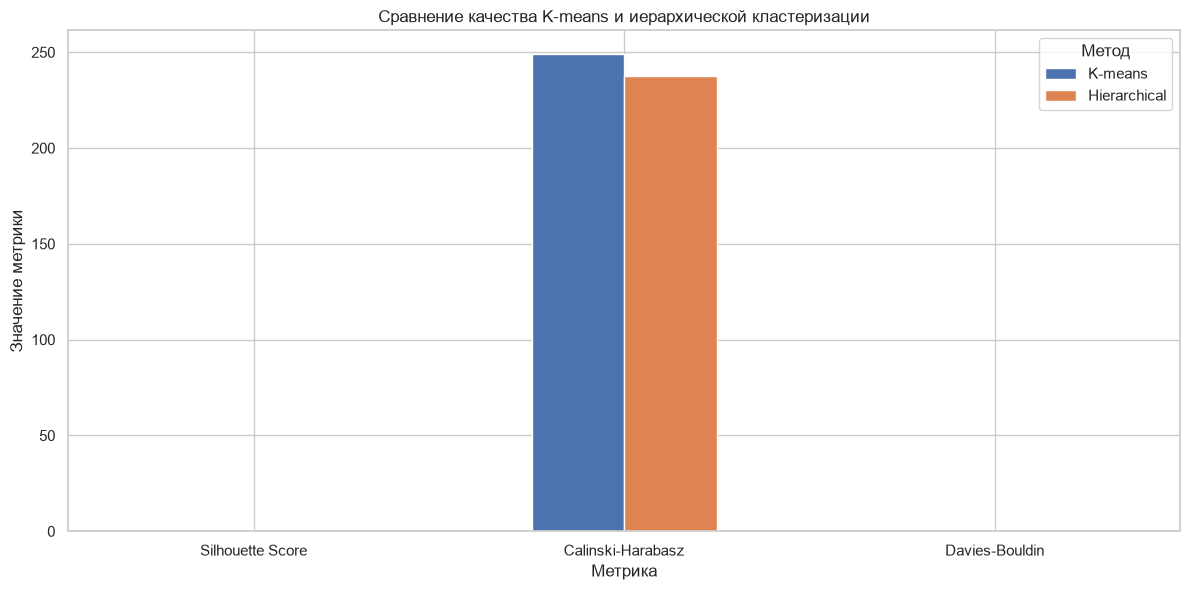

In [24]:
method_similarity_ari = adjusted_rand_score(kmeans_labels, hierarchical_labels)
print("\nСогласованность разбиений K-means и Hierarchical (ARI):", round(method_similarity_ari, 4))

comparison_df = pd.DataFrame({
    "Метрика": ["Silhouette Score", "Calinski-Harabasz", "Davies-Bouldin"],
    "K-means": [
        metrics_kmeans["Silhouette Score"],
        metrics_kmeans["Calinski-Harabasz"],
        metrics_kmeans["Davies-Bouldin"],
    ],
    "Hierarchical": [
        metrics_hierarchical["Silhouette Score"],
        metrics_hierarchical["Calinski-Harabasz"],
        metrics_hierarchical["Davies-Bouldin"],
    ],
})

print("\nСводная таблица сравнения методов:")
print(comparison_df.round(4).to_string(index=False))

comparison_df.set_index("Метрика").plot(kind="bar", figsize=(12, 6))
plt.title("Сравнение качества K-means и иерархической кластеризации")
plt.ylabel("Значение метрики")
plt.xticks(rotation=0)
plt.legend(title="Метод")
plt.tight_layout()
plt.show()

Высокая согласованность разбиений:

Индекс сходства разбиений между K-means и иерархической кластеризацией (метод Уорда) составляет $\text{ARI} = 0.973$, что говорит о практически полном совпадении формируемых групп объектов и высокой устойчивости структуры данных к выбору алгоритма.

Сравнение по внутренним метрикам качества:

По метрикам Silhouette Score ($0.5802$ против $0.5754$) и Calinski-Harabasz ($248.9034$ против $237.8259$) преимущество остаётся за K-means за счёт более компактного объединения объектов и лучшего соотношения межкластерной и внутрикластерной дисперсий.

По индексу Davies-Bouldin (чем меньше, тем лучше) методы показали почти одинаковые значения — $0.5976$ у K-means и $0.5963$ у иерархического алгоритма.

На графике сравнения метрик из-за разного масштаба шкал наиболее выражена разница по Calinski-Harabasz Index (около $249$ у K-means против около $238$ у Hierarchical), тогда как значения Silhouette Score и Davies-Bouldin лежат вблизи единицы и ниже, визуально сливаясь на общей шкале от $0$ до $250$.

В целом оба метода надёжно выделяют две основные морфологические группы ирисов, при этом K-means выглядит предпочтительнее по сводным метрикам компактности и разделимости.

In [26]:
print("ИТОГОВОЕ ЗАКЛЮЧЕНИЕ")
print(f"Объектов: {X.shape[0]}, числовых признаков: {X.shape[1]}")
print(f"Оптимальное k: K-means = {optimal_k}, Hierarchical = {best_k_hierarchical}")
print(
    f"K-means -> Silhouette: {metrics_kmeans['Silhouette Score']:.4f}, "
    f"CH: {metrics_kmeans['Calinski-Harabasz']:.4f}, "
    f"DB: {metrics_kmeans['Davies-Bouldin']:.4f}"
)
print(
    f"Hierarchical -> Silhouette: {metrics_hierarchical['Silhouette Score']:.4f}, "
    f"CH: {metrics_hierarchical['Calinski-Harabasz']:.4f}, "
    f"DB: {metrics_hierarchical['Davies-Bouldin']:.4f}"
)
print(f"Сходство разбиений двух методов (ARI): {method_similarity_ari:.4f}")
if y is not None:
    print(
        f"Внешний ARI -> K-means: {external_kmeans['ARI']:.4f}, "
        f"Hierarchical: {external_hierarchical['ARI']:.4f}"
    )

ИТОГОВОЕ ЗАКЛЮЧЕНИЕ
Объектов: 150, числовых признаков: 4
Оптимальное k: K-means = 2, Hierarchical = 2
K-means -> Silhouette: 0.5802, CH: 248.9034, DB: 0.5976
Hierarchical -> Silhouette: 0.5754, CH: 237.8259, DB: 0.5963
Сходство разбиений двух методов (ARI): 0.9730
Внешний ARI -> K-means: 0.5681, Hierarchical: 0.5438


Исходные данные и выбор числа кластеров:

Набор данных из $150$ наблюдений и $4$ числовых признаков был стандартизирован с помощью StandardScaler, после чего для обоих методов (K-means и иерархическая кластеризация методом Уорда) в качестве оптимального выбрано $k = 2$.

Качество кластеризации и сравнение методов:

Оба алгоритма показали высокое качество разбиения и практически идентичные результаты ($\text{ARI} = 0.9730$):

K-means: $\text{Silhouette} = 0.5802$, $\text{Calinski-Harabasz} = 248.9034$, $\text{Davies-Bouldin} = 0.5976$

Hierarchical: $\text{Silhouette} = 0.5754$, $\text{Calinski-Harabasz} = 237.8259$, $\text{Davies-Bouldin} = 0.5963$   

По сводным внутренним метрикам K-means демонстрирует небольшое преимущество над иерархической кластеризацией.   

Итого:

Сопоставление с истинной разметкой видов показало $\text{ARI} = 0.5681$ для K-means и $\text{ARI} = 0.5438$ для иерархического метода: при $k = 2$ алгоритмы безошибочно выделяют одну обособленную группу (setosa) и объединяют две близкие по признакам группы (versicolor и virginica) в единый кластер.

## Заключение

В ходе выполнения лабораторной работы №3 были изучены теоретические основы и практические аспекты кластерного анализа на примере набора данных Iris (150 наблюдений и 4 числовых признака: sepal_length, sepal_width, petal_length, petal_width) в постановке задачи обучения без учителя.

В процессе работы проведена первичная проверка условий применимости кластеризации, выполнена стандартизация числовых признаков с помощью StandardScaler, оценена информационная значимость признаков (по дисперсии, $F$-статистике ANOVA и взаимной информации с истинными классами), а также визуально проанализирована структура данных по матрице диаграмм рассеивания. Наибольшую информационную значимость для разделения наблюдений и согласованности с видами ирисов продемонстрировали признаки лепестка (petal_length и petal_width), тогда как ширина чашелистика (sepal_width) показала наименьшую самостоятельную разделимость. Для оценки кластеризации были реализованы алгоритмы K-means и иерархической кластеризации методом Уорда. На основе силуэтного анализа, метода локтя, дендрограммы и сводных внутренних метрик для обоих методов в качестве оптимального выбрано число кластеров $k = 2$ (при этом при детализации более крупного скопления прослеживается и вариант $k = 3$).

Сравнение моделей показало высокую согласованность разбиений ($\text{ARI} = 0.9730$) и устойчивость результатов: для K-means получены значения $\text{Silhouette} = 0.5802$, $\text{Calinski-Harabasz} = 248.9034$ и $\text{Davies-Bouldin} = 0.5976$, а для иерархической кластеризации методом Уорда — $\text{Silhouette} = 0.5754$, $\text{Calinski-Harabasz} = 237.8259$ и $\text{Davies-Bouldin} = 0.5963$. По сводным критериям компактности и отделимости K-means продемонстрировал небольшое преимущество за счёт более точного отнесения пограничного наблюдения.

Визуализация в пространстве главных компонент (первые две компоненты PCA суммарно объясняют 95.8% дисперсии: PC1 — 72.77%, PC2 — 23.03%) и сопоставление с истинными метками видов ($\text{ARI} = 0.5681$ для K-means и $\text{ARI} = 0.5438$ для иерархической кластеризации) наглядно подтвердили, что при $k = 2$ модели безошибочно выделяют один обособленный кластер (setosa, 50 объектов) и объединяют два морфологически близких вида (versicolor и virginica, по 50 объектов) в единую группу. Поставленные цели и задачи лабораторной работы выполнены в полном объёме.